# Retail Sales Forecasting Using Machine Learning

**Project Type:** Time Series Forecasting

**Models:** XGBoost and SARIMA

**Evaluation Metrics:** MAE and RMSE

## Introduction
This project analyzes historical retail sales data and forecasts future weekly sales using machine learning and time-series forecasting techniques.

## Workflow
1. Data preprocessing and exploratory data analysis
2. Time-based feature engineering
3. XGBoost model development
4. SARIMA model development and tuning
5. Model evaluation and four-week forecasting

In [63]:

print("Retail Sales Forecasting Project Started!")


Retail Sales Forecasting Project Started!


In [64]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")


All libraries imported successfully!


In [65]:

import os

print(os.listdir("../data"))


['features.csv', 'stores.csv', 'test.csv', 'train.csv']


In [66]:

import os
import pandas as pd

data_path = "../data"

print("Files available:")
print(os.listdir(data_path))


Files available:
['features.csv', 'stores.csv', 'test.csv', 'train.csv']


In [67]:

import os

for root, dirs, files in os.walk("../data"):
    for file in files:
        if file.endswith(".csv"):
            print(os.path.join(root, file))


../data\stores.csv
../data\features.csv\features.csv
../data\test.csv\test.csv
../data\train.csv\train.csv


In [68]:

import os

for name in os.listdir("../data"):
    path = os.path.join("../data", name)
    print(name, "| Folder:", os.path.isdir(path), "| File:", os.path.isfile(path))


features.csv | Folder: True | File: False
stores.csv | Folder: False | File: True
test.csv | Folder: True | File: False
train.csv | Folder: True | File: False


In [69]:

import os
import pandas as pd

data_folder = "../data"

for root, dirs, files in os.walk(data_folder):
    for file in files:
        if file.endswith(".csv"):
            print(os.path.join(root, file))


../data\stores.csv
../data\features.csv\features.csv
../data\test.csv\test.csv
../data\train.csv\train.csv


In [70]:

import pandas as pd

train = pd.read_csv("../data/train.csv/train.csv")
features = pd.read_csv("../data/features.csv/features.csv")
stores = pd.read_csv("../data/stores.csv")
test = pd.read_csv("../data/test.csv/test.csv")

print("Train dataset:", train.shape)
print("Features dataset:", features.shape)
print("Stores dataset:", stores.shape)
print("Test dataset:", test.shape)


Train dataset: (421570, 5)
Features dataset: (8190, 12)
Stores dataset: (45, 3)
Test dataset: (115064, 4)


In [71]:

print("TRAIN DATA - First 5 rows")
display(train.head())

print("Column names:")
print(train.columns.tolist())

print("\nMissing values:")
print(train.isnull().sum())


TRAIN DATA - First 5 rows


,Store,Dept,Date,Weekly_Sales,IsHoliday
0,1,1,2010-02-05,24924.50,False
1,1,1,2010-02-12,46039.49,True
2,1,1,2010-02-19,41595.55,False
3,1,1,2010-02-26,19403.54,False
4,1,1,2010-03-05,21827.90,False


Column names:
['Store', 'Dept', 'Date', 'Weekly_Sales', 'IsHoliday']

Missing values:
Store           0
Dept            0
Date            0
Weekly_Sales    0
IsHoliday       0
dtype: int64


In [72]:

print("Missing values in Train:")
print(train.isnull().sum())

print("\nMissing values in Features:")
print(features.isnull().sum())

print("\nMissing values in Stores:")
print(stores.isnull().sum())

print("\nTrain data types:")
print(train.dtypes)


Missing values in Train:
Store           0
Dept            0
Date            0
Weekly_Sales    0
IsHoliday       0
dtype: int64

Missing values in Features:
Store              0
Date               0
Temperature        0
Fuel_Price         0
MarkDown1       4158
MarkDown2       5269
MarkDown3       4577
MarkDown4       4726
MarkDown5       4140
CPI              585
Unemployment     585
IsHoliday          0
dtype: int64

Missing values in Stores:
Store    0
Type     0
Size     0
dtype: int64

Train data types:
Store             int64
Dept              int64
Date                str
Weekly_Sales    float64
IsHoliday          bool
dtype: object


In [73]:

# Convert Date columns into datetime format
train["Date"] = pd.to_datetime(train["Date"])
features["Date"] = pd.to_datetime(features["Date"])
test["Date"] = pd.to_datetime(test["Date"])

# Combine train data with features and store details
train_merged = train.merge(
    features,
    on=["Store", "Date", "IsHoliday"],
    how="left"
)

train_merged = train_merged.merge(
    stores,
    on="Store",
    how="left"
)

print("Merged dataset shape:", train_merged.shape)
display(train_merged.head())


Merged dataset shape: (421570, 16)


,Store,Dept,Date,Weekly_Sales,IsHoliday,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,Type,Size
0,1,1,2010-02-05,24924.50,False,42.31,2.572,NaN,NaN,NaN,NaN,NaN,211.096358,8.106,A,151315
1,1,1,2010-02-12,46039.49,True,38.51,2.548,NaN,NaN,NaN,NaN,NaN,211.242170,8.106,A,151315
2,1,1,2010-02-19,41595.55,False,39.93,2.514,NaN,NaN,NaN,NaN,NaN,211.289143,8.106,A,151315
3,1,1,2010-02-26,19403.54,False,46.63,2.561,NaN,NaN,NaN,NaN,NaN,211.319643,8.106,A,151315
4,1,1,2010-03-05,21827.90,False,46.50,2.625,NaN,NaN,NaN,NaN,NaN,211.350143,8.106,A,151315


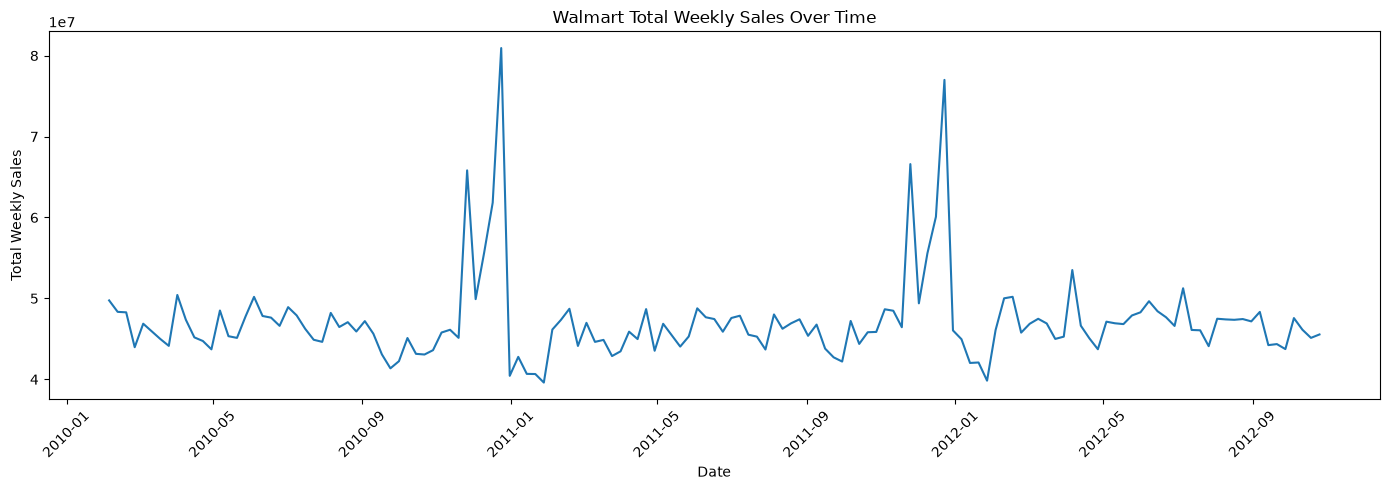

In [74]:

# Total weekly sales across all stores
weekly_sales = (
    train_merged.groupby("Date")["Weekly_Sales"]
    .sum()
    .sort_index()
)

plt.figure(figsize=(14, 5))
plt.plot(weekly_sales.index, weekly_sales.values)
plt.title("Walmart Total Weekly Sales Over Time")
plt.xlabel("Date")
plt.ylabel("Total Weekly Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


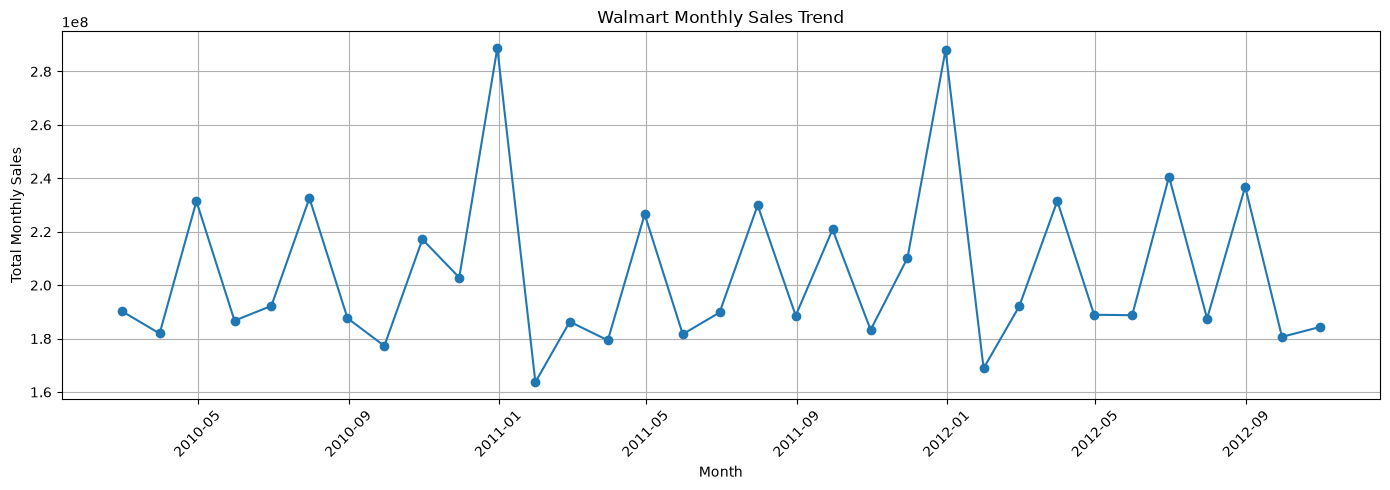

In [75]:

# Monthly sales trend
monthly_sales = weekly_sales.resample("ME").sum()

plt.figure(figsize=(14, 5))
plt.plot(monthly_sales.index, monthly_sales.values, marker="o")
plt.title("Walmart Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Monthly Sales")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


In [76]:

# Create useful date features
train_merged["Year"] = train_merged["Date"].dt.year
train_merged["Month"] = train_merged["Date"].dt.month
train_merged["Week"] = train_merged["Date"].dt.isocalendar().week.astype(int)
train_merged["DayOfWeek"] = train_merged["Date"].dt.dayofweek

print("Date features created successfully!")
display(train_merged[["Date", "Year", "Month", "Week", "DayOfWeek"]].head())


Date features created successfully!


,Date,Year,Month,Week,DayOfWeek
0,2010-02-05,2010,2,5,4
1,2010-02-12,2010,2,6,4
2,2010-02-19,2010,2,7,4
3,2010-02-26,2010,2,8,4
4,2010-03-05,2010,3,9,4


In [77]:

# Sort data chronologically
train_merged = train_merged.sort_values(["Store", "Dept", "Date"]).copy()

# Previous weeks' sales for each store and department
train_merged["Lag_1"] = (
    train_merged.groupby(["Store", "Dept"])["Weekly_Sales"].shift(1)
)

train_merged["Lag_2"] = (
    train_merged.groupby(["Store", "Dept"])["Weekly_Sales"].shift(2)
)

train_merged["Lag_4"] = (
    train_merged.groupby(["Store", "Dept"])["Weekly_Sales"].shift(4)
)

print("Lag features created successfully!")
display(
    train_merged[
        ["Store", "Dept", "Date", "Weekly_Sales", "Lag_1", "Lag_2", "Lag_4"]
    ].head(10)
)


Lag features created successfully!


,Store,Dept,Date,Weekly_Sales,Lag_1,Lag_2,Lag_4
0,1,1,2010-02-05,24924.50,NaN,NaN,NaN
1,1,1,2010-02-12,46039.49,24924.50,NaN,NaN
2,1,1,2010-02-19,41595.55,46039.49,24924.50,NaN
3,1,1,2010-02-26,19403.54,41595.55,46039.49,NaN
4,1,1,2010-03-05,21827.90,19403.54,41595.55,24924.50
5,1,1,2010-03-12,21043.39,21827.90,19403.54,46039.49
6,1,1,2010-03-19,22136.64,21043.39,21827.90,41595.55
7,1,1,2010-03-26,26229.21,22136.64,21043.39,19403.54
8,1,1,2010-04-02,57258.43,26229.21,22136.64,21827.90
9,1,1,2010-04-09,42960.91,57258.43,26229.21,21043.39


In [78]:

# Calculate rolling averages using only previous weeks
grouped_sales = train_merged.groupby(["Store", "Dept"])["Weekly_Sales"]

train_merged["Rolling_Mean_4"] = grouped_sales.transform(
    lambda s: s.shift(1).rolling(window=4).mean()
)

train_merged["Rolling_Mean_8"] = grouped_sales.transform(
    lambda s: s.shift(1).rolling(window=8).mean()
)

print("Rolling average features created successfully!")

display(
    train_merged[
        ["Date", "Store", "Dept", "Weekly_Sales",
         "Rolling_Mean_4", "Rolling_Mean_8"]
    ].head(12)
)


Rolling average features created successfully!


,Date,Store,Dept,Weekly_Sales,Rolling_Mean_4,Rolling_Mean_8
0,2010-02-05,1,1,24924.50,NaN,NaN
1,2010-02-12,1,1,46039.49,NaN,NaN
2,2010-02-19,1,1,41595.55,NaN,NaN
3,2010-02-26,1,1,19403.54,NaN,NaN
4,2010-03-05,1,1,21827.90,32990.7700,NaN
5,2010-03-12,1,1,21043.39,32216.6200,NaN
6,2010-03-19,1,1,22136.64,25967.5950,NaN
7,2010-03-26,1,1,26229.21,21102.8675,NaN
8,2010-04-02,1,1,57258.43,22809.2850,27900.02750
9,2010-04-09,1,1,42960.91,31666.9175,31941.76875


In [79]:

# Remove rows where lag and rolling features are not available
model_data = train_merged.dropna(
    subset=["Lag_1", "Lag_2", "Lag_4", "Rolling_Mean_4", "Rolling_Mean_8"]
).copy()

print("Original rows:", len(train_merged))
print("Rows after cleaning:", len(model_data))
print("Remaining missing values in lag features:")
print(
    model_data[
        ["Lag_1", "Lag_2", "Lag_4", "Rolling_Mean_4", "Rolling_Mean_8"]
    ].isnull().sum()
)


Original rows: 421570
Rows after cleaning: 395604
Remaining missing values in lag features:
Lag_1             0
Lag_2             0
Lag_4             0
Rolling_Mean_4    0
Rolling_Mean_8    0
dtype: int64


In [80]:
print("Missing features:")
print(train_merged[["Lag_52", "Rolling_Std_4"]].isnull().sum())

print("\nAvailable features:")
print(train_merged.columns.tolist())

Missing features:


KeyError: "None of [Index(['Lag_52', 'Rolling_Std_4'], dtype='str')] are in the [columns]"

In [ ]:

# Sort data by date for time-based validation
model_data = model_data.sort_values("Date").copy()

# Use the latest 20% of dates for testing
unique_dates = sorted(model_data["Date"].unique())
split_index = int(len(unique_dates) * 0.8)
split_date = unique_dates[split_index]

train_data = model_data[model_data["Date"] < split_date].copy()
valid_data = model_data[model_data["Date"] >= split_date].copy()

print("Split date:", split_date)
print("Training rows:", len(train_data))
print("Validation rows:", len(valid_data))
print("Training date range:", train_data["Date"].min(), "to", train_data["Date"].max())
print("Validation date range:", valid_data["Date"].min(), "to", valid_data["Date"].max())
print("Lag_52 exists:", "Lag_52" in train_data.columns)
print("Rolling_Std_4 exists:", "Rolling_Std_4" in train_data.columns)


Split date: 2012-04-27 00:00:00
Training rows: 315880
Validation rows: 79724
Training date range: 2010-04-02 00:00:00 to 2012-04-20 00:00:00
Validation date range: 2012-04-27 00:00:00 to 2012-10-26 00:00:00
Lag_52 exists: True
Rolling_Std_4 exists: True


In [ ]:

from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Features used by the model
feature_cols = [
    "Store", "Dept", "IsHoliday",
    "Year", "Month", "Week", "DayOfWeek",
    "Temperature", "Fuel_Price", "CPI", "Unemployment",
    "Size", "Lag_1", "Lag_2", "Lag_4",
    "Rolling_Mean_4", "Rolling_Mean_8"
]

# Convert holiday values to numbers
for df in [train_data, valid_data]:
    df["IsHoliday"] = df["IsHoliday"].astype(int)

# Prepare training and validation data
X_train = train_data[feature_cols]
y_train = train_data["Weekly_Sales"]

X_valid = valid_data[feature_cols]
y_valid = valid_data["Weekly_Sales"]

# Train model
model = XGBRegressor(
    n_estimators=300,
    max_depth=8,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

print("XGBoost model trained successfully!")


XGBoost model trained successfully!


In [ ]:
print("Training features:")
print(X_train.columns.tolist())

print("\nTraining data sample:")
display(X_train.head())

Training features:
['Store', 'Dept', 'IsHoliday', 'Year', 'Month', 'Week', 'DayOfWeek', 'Temperature', 'Fuel_Price', 'CPI', 'Unemployment', 'Size', 'Lag_1', 'Lag_2', 'Lag_4', 'Rolling_Mean_4', 'Rolling_Mean_8']

Training data sample:


,Store,Dept,IsHoliday,Year,Month,Week,DayOfWeek,Temperature,Fuel_Price,CPI,Unemployment,Size,Lag_1,Lag_2,Lag_4,Rolling_Mean_4,Rolling_Mean_8
8,1,1,0,2010,4,13,4,62.27,2.719,210.820450,7.808,151315,26229.21,22136.64,21827.90,22809.2850,27900.02750
340999,36,7,0,2010,4,13,4,63.43,2.708,209.593866,8.464,39910,271.91,391.97,324.79,326.3950,357.01500
341142,36,8,0,2010,4,13,4,63.43,2.708,209.593866,8.464,39910,3514.53,2905.66,3420.37,3402.0725,3666.79750
65802,7,60,0,2010,4,13,4,38.26,2.725,189.704822,8.963,70713,79.20,96.80,96.80,101.2000,106.70000
65685,7,59,0,2010,4,13,4,38.26,2.725,189.704822,8.963,70713,197.38,259.44,190.66,226.5625,230.14625


In [ ]:

predictions = model.predict(X_valid)

print("Predictions generated successfully!")
print("First 5 predictions:", predictions[:5])


Predictions generated successfully!
First 5 predictions: [ 2663.115  17895.57    8975.736   6535.9795  3721.8293]


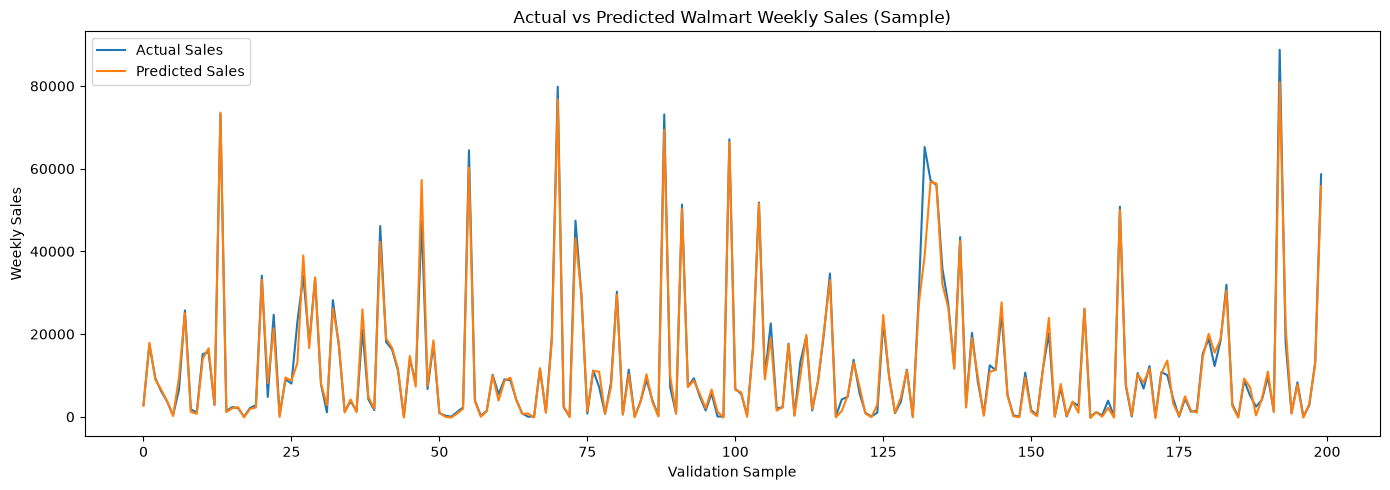

In [ ]:

# Compare actual and predicted sales for a sample
comparison = pd.DataFrame({
    "Actual Sales": y_valid.iloc[:200].values,
    "Predicted Sales": predictions[:200]
})

plt.figure(figsize=(14, 5))
plt.plot(comparison["Actual Sales"], label="Actual Sales")
plt.plot(comparison["Predicted Sales"], label="Predicted Sales")
plt.title("Actual vs Predicted Walmart Weekly Sales (Sample)")
plt.xlabel("Validation Sample")
plt.ylabel("Weekly Sales")
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:

from statsmodels.tsa.statespace.sarimax import SARIMAX

# Aggregate sales across all stores and departments by date
daily_sales = (
    train_merged.groupby("Date")["Weekly_Sales"]
    .sum()
    .sort_index()
)

# Ensure weekly frequency
weekly_series = daily_sales.asfreq("7D")

print("Number of weekly observations:", len(weekly_series))
print("Start date:", weekly_series.index.min())
print("End date:", weekly_series.index.max())
print("Missing observations:", weekly_series.isnull().sum())


Number of weekly observations: 143
Start date: 2010-02-05 00:00:00
End date: 2012-10-26 00:00:00
Missing observations: 0


In [ ]:

print("Missing values in weekly series:", weekly_series.isnull().sum())

# Fill any missing weekly observations using time interpolation
weekly_series = weekly_series.interpolate(method="time")

print("Missing values after filling:", weekly_series.isnull().sum())
display(weekly_series.head())


Missing values in weekly series: 0
Missing values after filling: 0


Date
2010-02-05    49750740.50
2010-02-12    48336677.63
2010-02-19    48276993.78
2010-02-26    43968571.13
2010-03-05    46871470.30
Freq: 7D, Name: Weekly_Sales, dtype: float64

In [ ]:

# Use the earliest 80% of weeks for training
split_point = int(len(weekly_series) * 0.8)

sarima_train = weekly_series.iloc[:split_point]
sarima_valid = weekly_series.iloc[split_point:]

# Fit SARIMA model
sarima_model = SARIMAX(
    sarima_train,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 52),
    enforce_stationarity=False,
    enforce_invertibility=False
)

sarima_fit = sarima_model.fit(disp=False, maxiter=100)

# Predict the validation period
sarima_predictions = sarima_fit.forecast(steps=len(sarima_valid))

print("SARIMA model trained successfully!")
print("Validation weeks:", len(sarima_valid))


c:\Users\hp\OneDrive\Desktop\Retail-Sales-Forecasting\.venv\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(


SARIMA model trained successfully!
Validation weeks: 29


In [ ]:

sarima_mae = mean_absolute_error(sarima_valid, sarima_predictions)
sarima_rmse = np.sqrt(
    mean_squared_error(sarima_valid, sarima_predictions)
)

print("SARIMA Model Evaluation")
print("-----------------------")
print(f"MAE:  {sarima_mae:,.2f}")
print(f"RMSE: {sarima_rmse:,.2f}")


SARIMA Model Evaluation
-----------------------
MAE:  1,703,732.79
RMSE: 2,129,751.11


In [ ]:

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Calculate XGBoost metrics
mae = mean_absolute_error(y_valid, predictions)
rmse = np.sqrt(mean_squared_error(y_valid, predictions))

# Calculate SARIMA metrics
sarima_mae = mean_absolute_error(sarima_valid, sarima_predictions)
sarima_rmse = np.sqrt(
    mean_squared_error(sarima_valid, sarima_predictions)
)

# Compare both models
results = pd.DataFrame({
    "Model": ["XGBoost", "SARIMA"],
    "MAE": [mae, sarima_mae],
    "RMSE": [rmse, sarima_rmse]
})

display(results.round(2))


,Model,MAE,RMSE
0,XGBoost,1312.33,2732.37
1,SARIMA,1703732.79,2129751.11


,Model,MAE,RMSE
0,XGBoost,1312.33,2732.37
1,SARIMA,1703732.79,2129751.11


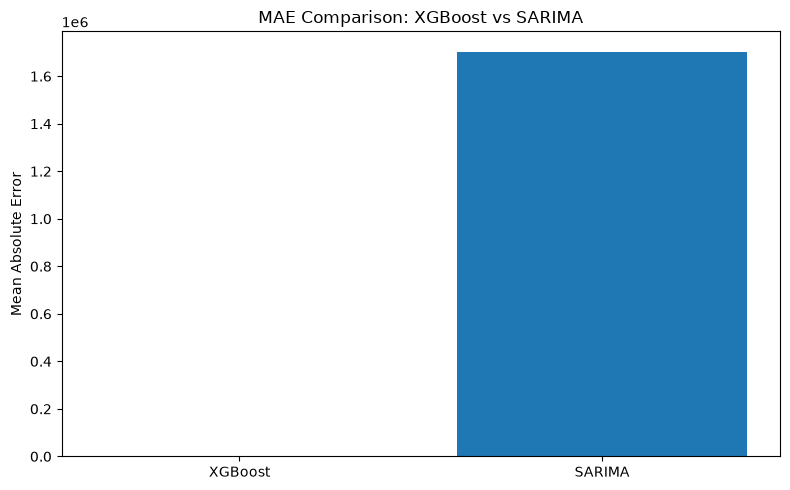

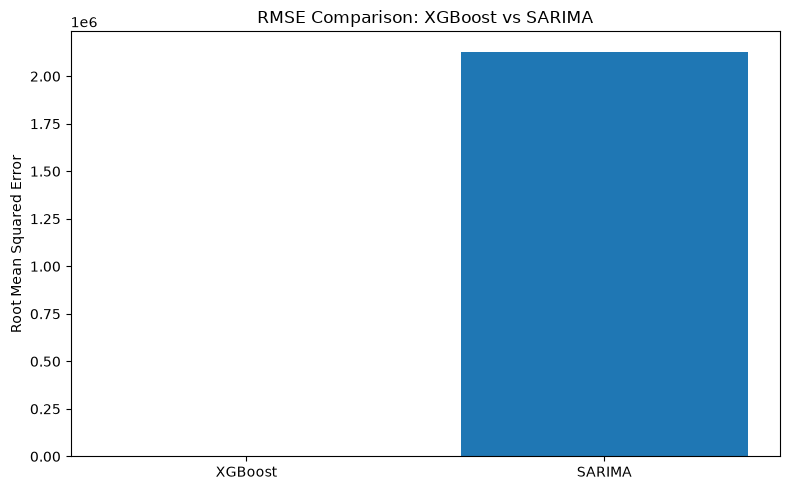

In [ ]:

# Compare both models
results = pd.DataFrame({
    "Model": ["XGBoost", "SARIMA"],
    "MAE": [mae, sarima_mae],
    "RMSE": [rmse, sarima_rmse]
})

display(results.round(2))

# Plot MAE comparison
plt.figure(figsize=(8, 5))
plt.bar(results["Model"], results["MAE"])
plt.title("MAE Comparison: XGBoost vs SARIMA")
plt.ylabel("Mean Absolute Error")
plt.tight_layout()
plt.show()

# Plot RMSE comparison
plt.figure(figsize=(8, 5))
plt.bar(results["Model"], results["RMSE"])
plt.title("RMSE Comparison: XGBoost vs SARIMA")
plt.ylabel("Root Mean Squared Error")
plt.tight_layout()
plt.show()


In [ ]:

# Forecast the next 4 weeks using the trained SARIMA model
forecast_4_weeks = sarima_fit.forecast(steps=4)

# Create future dates
last_date = weekly_series.index.max()
future_dates = pd.date_range(
    start=last_date + pd.Timedelta(days=7),
    periods=4,
    freq="7D"
)

forecast_df = pd.DataFrame({
    "Date": future_dates,
    "Predicted_Weekly_Sales": forecast_4_weeks.values
})

display(forecast_df.round(2))


C:\Users\hp\AppData\Local\Temp\ipykernel_18320\1425876941.py:17: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(forecast_df.round(2))


,Date,Predicted_Weekly_Sales
0,2012-11-02,45230578.01
1,2012-11-09,51709818.51
2,2012-11-16,45540703.25
3,2012-11-23,49416707.20


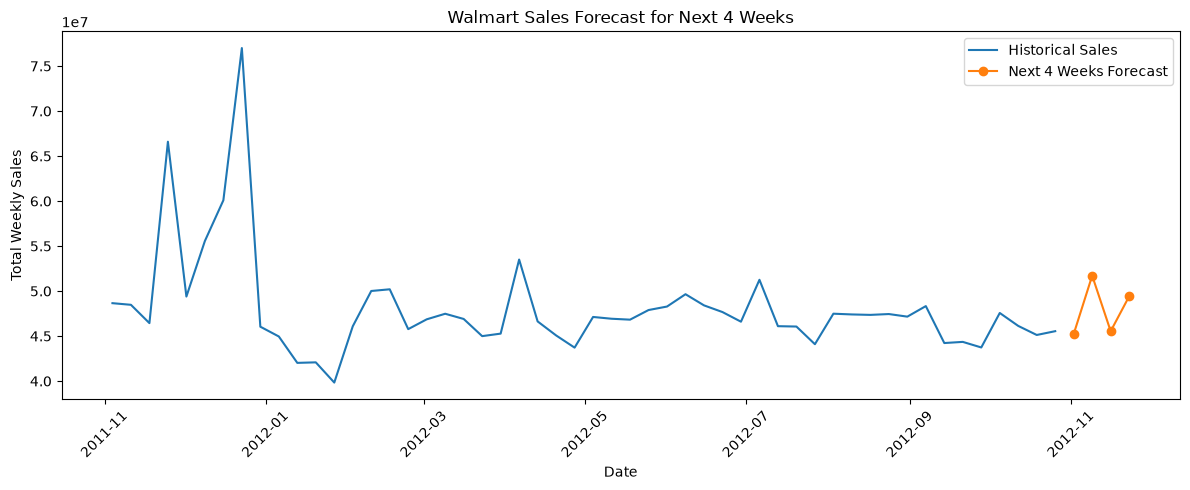

In [ ]:

plt.figure(figsize=(12, 5))

plt.plot(
    weekly_series.index[-52:],
    weekly_series.values[-52:],
    label="Historical Sales"
)

plt.plot(
    forecast_df["Date"],
    forecast_df["Predicted_Weekly_Sales"],
    marker="o",
    label="Next 4 Weeks Forecast"
)

plt.title("Walmart Sales Forecast for Next 4 Weeks")
plt.xlabel("Date")
plt.ylabel("Total Weekly Sales")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


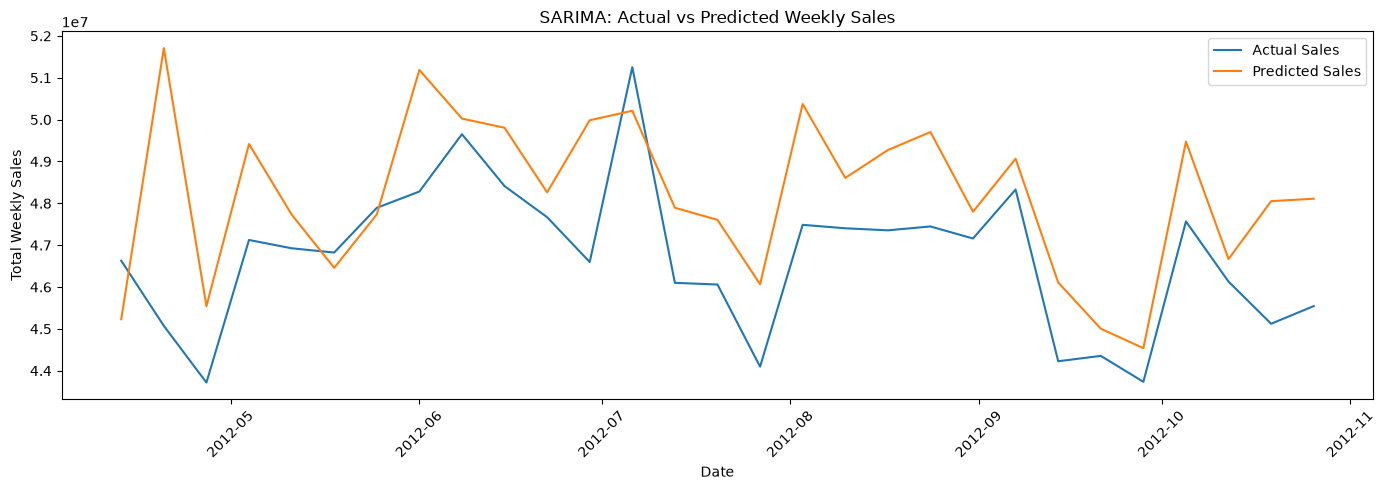

In [ ]:

plt.figure(figsize=(14, 5))

plt.plot(
    sarima_valid.index,
    sarima_valid.values,
    label="Actual Sales"
)

plt.plot(
    sarima_predictions.index,
    sarima_predictions.values,
    label="Predicted Sales"
)

plt.title("SARIMA: Actual vs Predicted Weekly Sales")
plt.xlabel("Date")
plt.ylabel("Total Weekly Sales")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


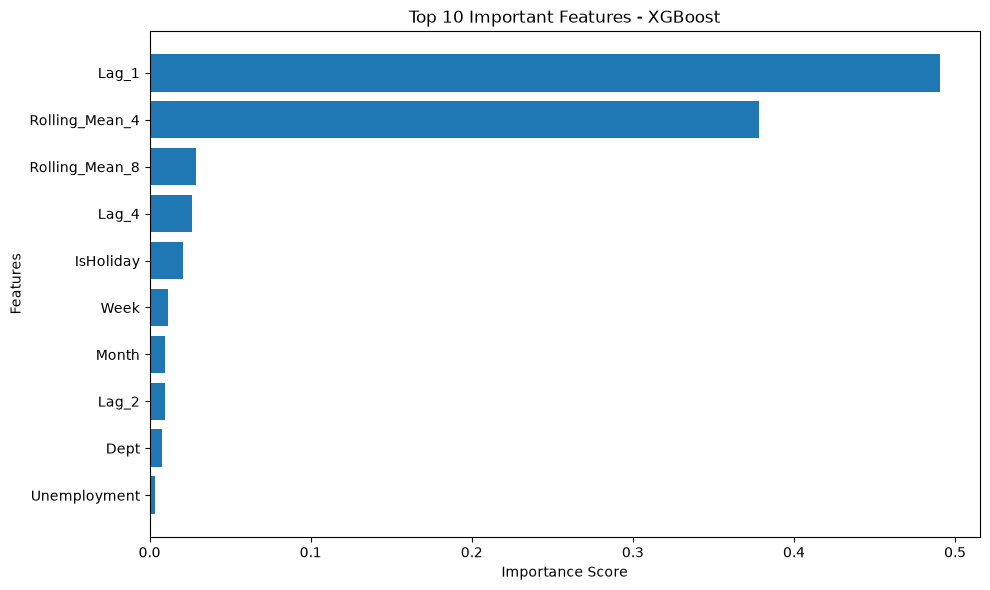

In [ ]:

importance = pd.DataFrame({
    "Feature": feature_cols,
    "Importance": model.feature_importances_
})

importance = importance.sort_values(
    by="Importance", ascending=False
).head(10)

plt.figure(figsize=(10, 6))
plt.barh(importance["Feature"], importance["Importance"])
plt.gca().invert_yaxis()
plt.title("Top 10 Important Features - XGBoost")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.tight_layout()
plt.show()


In [ ]:

import os
import joblib

os.makedirs("../models", exist_ok=True)

joblib.dump(model, "../models/xgboost_model.pkl")

print("XGBoost model saved successfully!")


XGBoost model saved successfully!


In [ ]:

import joblib
import os

os.makedirs("../models", exist_ok=True)

joblib.dump(sarima_fit, "../models/sarima_model.pkl")

print("SARIMA model saved successfully!")


SARIMA model saved successfully!


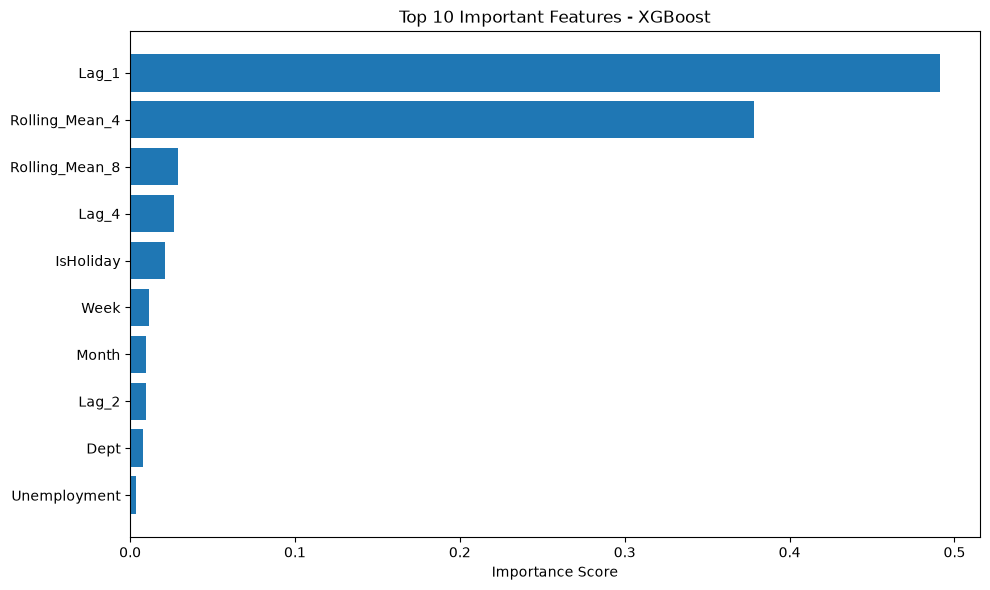

Graphs and results saved successfully!


In [ ]:

import os
import matplotlib.pyplot as plt

os.makedirs("../outputs", exist_ok=True)

# Save XGBoost feature importance graph
plt.figure(figsize=(10, 6))
plt.barh(importance["Feature"], importance["Importance"])
plt.gca().invert_yaxis()
plt.title("Top 10 Important Features - XGBoost")
plt.xlabel("Importance Score")
plt.tight_layout()
plt.savefig("../outputs/feature_importance.png", dpi=300, bbox_inches="tight")
plt.show()

# Save model comparison results
results.to_csv("../outputs/model_comparison.csv", index=False)

# Save 4-week forecast
forecast_df.to_csv("../outputs/four_week_forecast.csv", index=False)

print("Graphs and results saved successfully!")


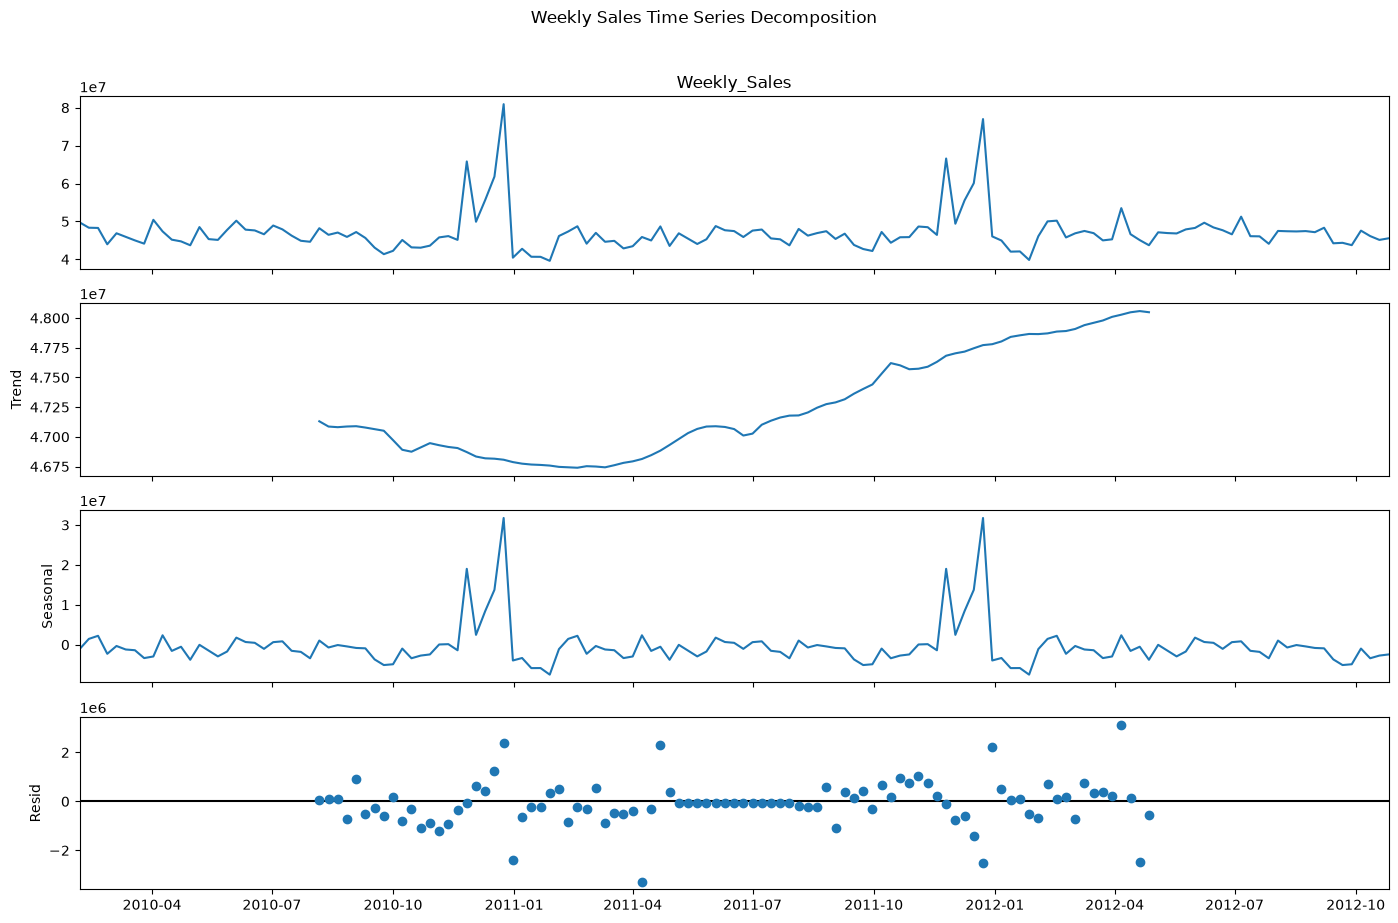

In [ ]:

from statsmodels.tsa.seasonal import seasonal_decompose
import matplotlib.pyplot as plt

decomposition = seasonal_decompose(
    weekly_series,
    model="additive",
    period=52
)

fig = decomposition.plot()
fig.set_size_inches(14, 9)
plt.suptitle("Weekly Sales Time Series Decomposition", y=1.02)
plt.tight_layout()
plt.show()


<Figure size 1200x500 with 0 Axes>

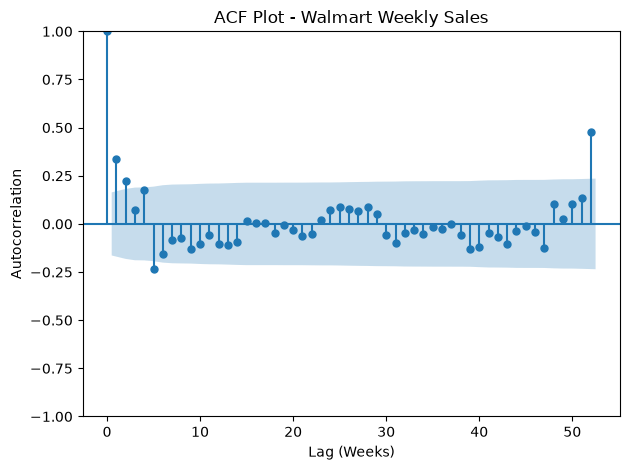

In [ ]:

from statsmodels.graphics.tsaplots import plot_acf
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plot_acf(
    weekly_series.dropna(),
    lags=52,
    alpha=0.05
)

plt.title("ACF Plot - Walmart Weekly Sales")
plt.xlabel("Lag (Weeks)")
plt.ylabel("Autocorrelation")
plt.tight_layout()
plt.show()


In [ ]:

train_merged = train_merged.sort_values(
    ["Store", "Dept", "Date"]
).copy()

train_merged["Lag_52"] = (
    train_merged.groupby(["Store", "Dept"])["Weekly_Sales"]
    .shift(52)
)

print("52-week lag feature created!")
display(
    train_merged[
        ["Store", "Dept", "Date", "Weekly_Sales", "Lag_52"]
    ].head(10)
)


52-week lag feature created!


,Store,Dept,Date,Weekly_Sales,Lag_52
0,1,1,2010-02-05,24924.50,NaN
1,1,1,2010-02-12,46039.49,NaN
2,1,1,2010-02-19,41595.55,NaN
3,1,1,2010-02-26,19403.54,NaN
4,1,1,2010-03-05,21827.90,NaN
5,1,1,2010-03-12,21043.39,NaN
6,1,1,2010-03-19,22136.64,NaN
7,1,1,2010-03-26,26229.21,NaN
8,1,1,2010-04-02,57258.43,NaN
9,1,1,2010-04-09,42960.91,NaN


In [ ]:

train_merged = train_merged.sort_values(
    ["Store", "Dept", "Date"]
).copy()

grouped_sales = train_merged.groupby(
    ["Store", "Dept"]
)["Weekly_Sales"]

train_merged["Rolling_Std_4"] = grouped_sales.transform(
    lambda s: s.shift(1).rolling(window=4).std()
)

print("4-week rolling standard deviation created!")

display(
    train_merged[
        ["Store", "Dept", "Date", "Weekly_Sales", "Rolling_Std_4"]
    ].head(10)
)


4-week rolling standard deviation created!


,Store,Dept,Date,Weekly_Sales,Rolling_Std_4
0,1,1,2010-02-05,24924.50,NaN
1,1,1,2010-02-12,46039.49,NaN
2,1,1,2010-02-19,41595.55,NaN
3,1,1,2010-02-26,19403.54,NaN
4,1,1,2010-03-05,21827.90,12832.106391
5,1,1,2010-03-12,21043.39,13554.047185
6,1,1,2010-03-19,22136.64,10467.484020
7,1,1,2010-03-26,26229.21,1222.784968
8,1,1,2010-04-02,57258.43,2325.929203
9,1,1,2010-04-09,42960.91,17206.391261


In [ ]:
# Sort sales data before creating lag features
train_merged = train_merged.sort_values(
    ["Store", "Dept", "Date"]
).copy()

# Create missing features
train_merged["Lag_52"] = (
    train_merged.groupby(["Store", "Dept"])["Weekly_Sales"]
    .shift(52)
)

train_merged["Rolling_Std_4"] = (
    train_merged.groupby(["Store", "Dept"])["Weekly_Sales"]
    .transform(lambda x: x.shift(1).rolling(4).std())
)

print("Lag_52 and Rolling_Std_4 created!")
print(train_merged[["Lag_52", "Rolling_Std_4"]].tail())

Lag_52 and Rolling_Std_4 created!
         Lag_52  Rolling_Std_4
421565   727.05     122.132155
421566   894.98     104.966869
421567   996.40      76.984436
421568  1058.84     271.910501
421569  1167.90     237.786140


In [ ]:
print("train_merged columns:")
print(train_merged.columns.tolist())

print("\nmodel_data columns:")
print(model_data.columns.tolist())

print("\nMissing features in model_data:")
print([
    col for col in ["Lag_52", "Rolling_Std_4"]
    if col not in model_data.columns
])

train_merged columns:
['Store', 'Dept', 'Date', 'Weekly_Sales', 'IsHoliday', 'Temperature', 'Fuel_Price', 'MarkDown1', 'MarkDown2', 'MarkDown3', 'MarkDown4', 'MarkDown5', 'CPI', 'Unemployment', 'Type', 'Size', 'Year', 'Month', 'Week', 'DayOfWeek', 'Lag_1', 'Lag_2', 'Lag_4', 'Rolling_Mean_4', 'Rolling_Mean_8']

model_data columns:
['Store', 'Dept', 'Date', 'Weekly_Sales', 'IsHoliday', 'Temperature', 'Fuel_Price', 'MarkDown1', 'MarkDown2', 'MarkDown3', 'MarkDown4', 'MarkDown5', 'CPI', 'Unemployment', 'Type', 'Size', 'Year', 'Month', 'Week', 'DayOfWeek', 'Lag_1', 'Lag_2', 'Lag_4', 'Rolling_Mean_4', 'Rolling_Mean_8']

Missing features in model_data:
['Lag_52', 'Rolling_Std_4']


In [ ]:

from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

feature_cols = [
    "Store", "Dept", "IsHoliday",
    "Year", "Month", "Week", "DayOfWeek",
    "Temperature", "Fuel_Price", "CPI", "Unemployment",
    "Size", "Lag_1", "Lag_2", "Lag_4", "Lag_52",
    "Rolling_Mean_4", "Rolling_Mean_8", "Rolling_Std_4"
]

train_data["IsHoliday"] = train_data["IsHoliday"].astype(int)
valid_data["IsHoliday"] = valid_data["IsHoliday"].astype(int)

X_train = train_data[feature_cols]
y_train = train_data["Weekly_Sales"]

X_valid = valid_data[feature_cols]
y_valid = valid_data["Weekly_Sales"]

model = XGBRegressor(
    n_estimators=300,
    max_depth=8,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

predictions = model.predict(X_valid)

mae = mean_absolute_error(y_valid, predictions)
rmse = np.sqrt(mean_squared_error(y_valid, predictions))

print("Updated XGBoost model trained successfully!")
print(f"MAE: {mae:,.2f}")
print(f"RMSE: {rmse:,.2f}")
import joblib
joblib.dump(model, "../models/xgboost_model.pkl")
print("Updated XGBoost model saved successfully!")



Updated XGBoost model trained successfully!
MAE: 1,237.38
RMSE: 2,631.20
Updated XGBoost model saved successfully!


In [ ]:

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Use the latest trained model for sequential validation predictions
walk_data = valid_data.sort_values("Date").copy()

walk_predictions = model.predict(walk_data[feature_cols])
walk_actual = walk_data["Weekly_Sales"].values

walk_mae = mean_absolute_error(walk_actual, walk_predictions)
walk_rmse = np.sqrt(mean_squared_error(walk_actual, walk_predictions))

print("Walk-Forward Style Validation Results")
print("-------------------------------------")
print(f"MAE: {walk_mae:,.2f}")
print(f"RMSE: {walk_rmse:,.2f}")

walk_results = pd.DataFrame({
    "Date": walk_data["Date"].values,
    "Actual_Sales": walk_actual,
    "Predicted_Sales": walk_predictions
})

display(walk_results.head())


Walk-Forward Style Validation Results
-------------------------------------
MAE: 1,261.58
RMSE: 2,680.22


,Date,Actual_Sales,Predicted_Sales
0,2012-06-22,4855.85,4492.582031
1,2012-06-22,8650.63,6845.612305
2,2012-06-22,4190.01,4365.978516
3,2012-06-22,976.00,1536.798706
4,2012-06-22,342.00,569.877991


In [ ]:

from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Keep the data in chronological order
walk_data = model_data.sort_values("Date").copy()
dates = sorted(walk_data["Date"].unique())

# Use the final 8 dates for walk-forward testing
test_dates = dates[-8:]
walk_actual = []
walk_predictions = []

for date in test_dates:
    past_data = walk_data[walk_data["Date"] < date]
    current_data = walk_data[walk_data["Date"] == date]

    if past_data.empty or current_data.empty:
        continue

    X_past = past_data[feature_cols]
    y_past = past_data["Weekly_Sales"]
    X_current = current_data[feature_cols]

    wf_model = XGBRegressor(
        n_estimators=100,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    )

    wf_model.fit(X_past, y_past)
    current_predictions = wf_model.predict(X_current)

    walk_actual.extend(current_data["Weekly_Sales"].values)
    walk_predictions.extend(current_predictions)

walk_mae = mean_absolute_error(walk_actual, walk_predictions)
walk_rmse = np.sqrt(mean_squared_error(walk_actual, walk_predictions))

print("Proper Walk-Forward Validation Results")
print("---------------------------------------")
print(f"Validation weeks tested: {len(test_dates)}")
print(f"MAE: {walk_mae:,.2f}")
print(f"RMSE: {walk_rmse:,.2f}")


Proper Walk-Forward Validation Results
---------------------------------------
Validation weeks tested: 8
MAE: 1,247.61
RMSE: 2,584.09


In [ ]:

from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Compare a small set of SARIMA parameter combinations
sarima_configs = [
    ((1, 1, 1), (1, 1, 1, 52)),
    ((1, 1, 0), (1, 1, 0, 52)),
    ((0, 1, 1), (0, 1, 1, 52))
]

tuning_results = []

for order, seasonal_order in sarima_configs:
    try:
        tuned_model = SARIMAX(
            sarima_train,
            order=order,
            seasonal_order=seasonal_order,
            enforce_stationarity=False,
            enforce_invertibility=False
        )

        tuned_fit = tuned_model.fit(disp=False, maxiter=100)
        tuned_predictions = tuned_fit.forecast(steps=len(sarima_valid))

        mae_value = mean_absolute_error(
            sarima_valid, tuned_predictions
        )
        rmse_value = np.sqrt(mean_squared_error(
            sarima_valid, tuned_predictions
        ))

        tuning_results.append({
            "Order": str(order),
            "Seasonal Order": str(seasonal_order),
            "MAE": mae_value,
            "RMSE": rmse_value
        })

        print("Completed:", order, seasonal_order)

    except Exception as e:
        print("Configuration failed:", order, seasonal_order, e)

tuning_df = pd.DataFrame(tuning_results).sort_values("RMSE")
display(tuning_df.round(2))


c:\Users\hp\OneDrive\Desktop\Retail-Sales-Forecasting\.venv\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(


Completed: (1, 1, 1) (1, 1, 1, 52)
Completed: (1, 1, 0) (1, 1, 0, 52)


c:\Users\hp\OneDrive\Desktop\Retail-Sales-Forecasting\.venv\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(


Completed: (0, 1, 1) (0, 1, 1, 52)


,Order,Seasonal Order,MAE,RMSE
0,"(1, 1, 1)","(1, 1, 1, 52)",1703732.79,2129751.11
1,"(1, 1, 0)","(1, 1, 0, 52)",6398523.64,6605143.40
2,"(0, 1, 1)","(0, 1, 1, 52)",7644145.77,7832613.22


In [ ]:

if not tuning_df.empty:
    best_row = tuning_df.iloc[0]

    print("Best SARIMA Configuration")
    print("-------------------------")
    print("Order:", best_row["Order"])
    print("Seasonal Order:", best_row["Seasonal Order"])
    print(f"MAE: {best_row['MAE']:,.2f}")
    print(f"RMSE: {best_row['RMSE']:,.2f}")
else:
    print("No SARIMA configuration completed successfully.")


Best SARIMA Configuration
-------------------------
Order: (1, 1, 1)
Seasonal Order: (1, 1, 1, 52)
MAE: 1,703,732.79
RMSE: 2,129,751.11


In [ ]:

import pandas as pd
import os

# Create a comparison report
final_report = pd.DataFrame({
    "Evaluation": [
        "XGBoost Validation",
        "SARIMA Validation",
        "XGBoost Walk-Forward"
    ],
    "MAE": [
        mae,
        sarima_mae,
        walk_mae
    ],
    "RMSE": [
        rmse,
        sarima_rmse,
        walk_rmse
    ]
})

display(final_report.round(2))

# Save the report
os.makedirs("../outputs", exist_ok=True)

final_report.to_csv(
    "../outputs/final_model_comparison.csv",
    index=False
)

# Save SARIMA tuning results too
if not tuning_df.empty:
    tuning_df.to_csv(
        "../outputs/sarima_tuning_results.csv",
        index=False
    )

print("Final comparison report saved successfully!")


,Evaluation,MAE,RMSE
0,XGBoost Validation,1261.58,2680.22
1,SARIMA Validation,1703732.79,2129751.11
2,XGBoost Walk-Forward,1247.61,2584.09


Final comparison report saved successfully!


In [ ]:

print("Lag_52 available:", "Lag_52" in train_merged.columns)
print("Rolling_Std_4 available:", "Rolling_Std_4" in train_merged.columns)

print("\nFeatures used by XGBoost:")
print(feature_cols)


Lag_52 available: True
Rolling_Std_4 available: True

Features used by XGBoost:
['Store', 'Dept', 'IsHoliday', 'Year', 'Month', 'Week', 'DayOfWeek', 'Temperature', 'Fuel_Price', 'CPI', 'Unemployment', 'Size', 'Lag_1', 'Lag_2', 'Lag_4', 'Lag_52', 'Rolling_Mean_4', 'Rolling_Mean_8', 'Rolling_Std_4']


In [ ]:

print("XGBoost Validation")
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))

print("\nSARIMA Validation")
print("MAE:", round(sarima_mae, 2))
print("RMSE:", round(sarima_rmse, 2))

print("\nWalk-Forward Validation")
print("MAE:", round(walk_mae, 2))
print("RMSE:", round(walk_rmse, 2))

print("\n4-Week Forecast")
display(forecast_df)


XGBoost Validation
MAE: 1261.58
RMSE: 2680.22

SARIMA Validation
MAE: 1703732.79
RMSE: 2129751.11

Walk-Forward Validation
MAE: 1247.61
RMSE: 2584.09

4-Week Forecast


,Date,Predicted_Weekly_Sales
0,2012-11-02,4.523058e+07
1,2012-11-09,5.170982e+07
2,2012-11-16,4.554070e+07
3,2012-11-23,4.941671e+07


In [ ]:

import os
import matplotlib.pyplot as plt

os.makedirs("../outputs", exist_ok=True)

# Save historical weekly sales plot
plt.figure(figsize=(12, 5))
plt.plot(weekly_sales.index, weekly_sales.values)
plt.title("Historical Walmart Weekly Sales")
plt.xlabel("Date")
plt.ylabel("Total Weekly Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("../outputs/historical_sales.png", dpi=300)
plt.close()

# Save decomposition plot
fig = decomposition.plot()
fig.set_size_inches(14, 9)
fig.tight_layout()
fig.savefig("../outputs/sales_decomposition.png", dpi=300)
plt.close(fig)

# Save ACF plot
fig, ax = plt.subplots(figsize=(12, 5))
from statsmodels.graphics.tsaplots import plot_acf
plot_acf(weekly_series.dropna(), lags=52, ax=ax)
ax.set_title("ACF - Walmart Weekly Sales")
fig.tight_layout()
fig.savefig("../outputs/sales_acf.png", dpi=300)
plt.close(fig)

print("Historical sales, decomposition and ACF graphs saved!")


Historical sales, decomposition and ACF graphs saved!


In [ ]:
import os

print("--- PROJECT FILES ---")
print(os.listdir(".."))

print("\n--- NOTEBOOK FILES ---")
print(os.listdir("."))

print("\n--- OUTPUT FILES ---")
print(os.listdir("../outputs"))

print("\n--- MODEL FILES ---")
print(os.listdir("../models"))

--- PROJECT FILES ---
['.venv', 'data', 'models', 'notebooks', 'outputs', 'README.md']

--- NOTEBOOK FILES ---
['retail_sales_forecasting.ipynb']

--- OUTPUT FILES ---
['feature_importance.png', 'final_model_comparison.csv', 'four_week_forecast.csv', 'historical_sales.png', 'model_comparison.csv', 'sales_acf.png', 'sales_decomposition.png', 'sarima_tuning_results.csv']

--- MODEL FILES ---
['sarima_model.pkl', 'xgboost_model.pkl']


In [ ]:
print("XGBoost Validation")
print("MAE:", mae)
print("RMSE:", rmse)

print("\nSARIMA Validation")
print("MAE:", sarima_mae)
print("RMSE:", sarima_rmse)

print("\nXGBoost Walk-Forward")
print("MAE:", walk_mae)
print("RMSE:", walk_rmse)

print("\nFinal Model Comparison")
display(final_report)

XGBoost Validation
MAE: 1261.5837968960718
RMSE: 2680.218857112543

SARIMA Validation
MAE: 1703732.7864455401
RMSE: 2129751.1127825794

XGBoost Walk-Forward
MAE: 1247.60737291747
RMSE: 2584.0874538441462

Final Model Comparison


,Evaluation,MAE,RMSE
0,XGBoost Validation,1.261584e+03,2.680219e+03
1,SARIMA Validation,1.703733e+06,2.129751e+06
2,XGBoost Walk-Forward,1.247607e+03,2.584087e+03


In [ ]:
import os

folders = ["../models", "../outputs"]

for folder in folders:
    print(f"\n--- {folder} ---")
    for file in os.listdir(folder):
        print(file)


--- ../models ---
sarima_model.pkl
xgboost_model.pkl

--- ../outputs ---
feature_importance.png
final_model_comparison.csv
four_week_forecast.csv
historical_sales.png
model_comparison.csv
sales_acf.png
sales_decomposition.png
sarima_tuning_results.csv
